# Extended record: data check (1996-2026)

## Purpose
Notebooks 00-04 run on the 2016-2026 SST record, which gives a baseline of only 10-11 years. This notebook checks the extended file I downloaded to support a 30-year baseline, before it goes into the pipeline.

## Data
- **Product:** SST_MED_SST_L4_REP_OBSERVATIONS_010_021 (Copernicus Marine), daily, 0.05° grid
- **Variable:** `analysed_sst` (kelvin)
- **Box:** lat 40.5-44.5, lon 2-14, identical to the original download, so thresholds stay comparable cell by cell
- **Period:** 01-01-1996 to 24-10-2026, downloaded on 23-11-2026
- **File:** `med_sst_1996_2026.nc`, 410.69 MB, not versioned (`data/raw`)
- **Why 1996:** the 2016-2026 file I already had ends on 21-06-2026; the 20 years before 2016 complete a 30-year window
- **Known limits:** the product lags real time by about a month, and 2026 is incomplete

## Checks
1. Time axis: first and last day, number of time steps vs calendar days (11,255 expected: 30 × 365 + 8 leap days + 297)
2. NaN count over the full grid: 7,184 of 19,120 cells (37.6%) on every one of the 11,255 days, so the land mask is constant and there are no missing-data gaps
3. Sanity check of temperature range over the full record: 4.25 to 30.79 °C, with the minimum located (07-01-2019, northern Adriatic) and checked against neighbouring days and a map

## What I expect before running the detection
With a 30-year baseline the threshold should drop, so I expect more events than the 253,145 found with the 10-11 year baseline, and a higher median duration than 8 days. To be compared with the results in a later notebook.

## Status
Time axis verified: 11,255 steps, matching the calendar (checked in code). NaN check: constant 7,184 NaN per day (land mask), no gaps.

Temperature range: 4.25 to 30.79 °C, plausible for the region.

In [1]:
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

DATA_PATH = "../data/raw/med_sst_1996_2026.nc"

In [2]:
# Load the downloaded file
ds = xr.open_dataset(DATA_PATH)
print(ds)

<xarray.Dataset> Size: 2GB
Dimensions:       (time: 11255, latitude: 80, longitude: 239)
Coordinates:
  * time          (time) datetime64[ns] 90kB 1996-01-01 ... 2026-10-24
  * latitude      (latitude) float32 320B 40.51 40.56 40.61 ... 44.42 44.47
  * longitude     (longitude) float32 956B 2.044 2.094 2.144 ... 13.9 13.95
Data variables:
    analysed_sst  (time, latitude, longitude) float64 2GB ...
Attributes: (12/51)
    Conventions:                CF-1.4 
    DSD_entry_id:               -GOS-L4HRfnd-MED
    Metadata_Conventions:       Unidata Dataset Discovery v1.0
    Scaling_Equation:           (scale_factor*data) + add_offset
    acknowledgment:             Please acknowledge the use of these data with...
    cdm_data_type:              grid
    ...                         ...
    time_coverage_end:          20240928T070000Z
    time_coverage_start:        20240927T190000Z
    title:                      Mediterranean Sea SST Analysis L4, Reprocesse...
    uuid:                  

In [3]:
# Check overall value range and NaN count across the full grid for day 1,
# to confirm land cells are masked as NaN and sea temperatures are plausible
sst_day1 = ds["analysed_sst"].isel(time=0)

print("Minimum value (K):", sst_day1.min().values)
print("Maximum value (K):", sst_day1.max().values)
print("Number of NaN:", sst_day1.isnull().sum().values)
print("Total number of cells:", sst_day1.size)

Minimum value (K): 282.17999369464815
Maximum value (K): 289.86999352276325
Number of NaN: 7184
Total number of cells: 19120


In [4]:
# Count of NaN per day over the extended period
nan_per_day = ds["analysed_sst"].isnull().sum(dim=["latitude", "longitude"])

print(nan_per_day.min().values, nan_per_day.max().values)

7184 7184


***Results***: NaN count over the full grid. 7,184 of 19,120 cells (37.6%) on every one of the 11,255 days, so the land mask is constant and there are no missing-data gaps

In [5]:
# Check the time axis is complete: one time step per calendar day
expected_days = pd.date_range(ds.time.min().values, ds.time.max().values, freq="D")

print(len(expected_days), ds.sizes["time"])

11255 11255


***Results***: Time axis. 11,255 calendar days between 01-01-1996 and 24-10-2026 against 11,255 time steps in the file, so there is exactly one time step per day, with no gaps or duplicates.

In [6]:
# Check the temperature range over the full record (kelvin and Celsius),
# to catch fill values or outliers that the day-1 check cannot show
sst_min = ds["analysed_sst"].min().values
sst_max = ds["analysed_sst"].max().values

print("Minimum (K):", sst_min, "| (C):", sst_min - 273.15)
print("Maximum (K):", sst_max, "| (C):", sst_max - 273.15)

Minimum (K): 277.3999938014895 | (C): 4.249993801489495
Maximum (K): 303.93999320827425 | (C): 30.789993208274268


In [7]:
# Locate the coldest value: where and when it occurs
sst = ds["analysed_sst"]
coldest = sst.where(sst == sst.min(), drop=True)

print(coldest.time.values, coldest.latitude.values, coldest.longitude.values)

['2019-01-07T00:00:00.000000000'] [44.47011] [12.352987]


In [8]:
# How many cells per day are within 2 degrees of the record minimum,
# keeping only the days where there is at least one
near_min_per_day = (sst <= sst.min() + 2).sum(dim=["latitude", "longitude"])
cold_days = near_min_per_day.where(near_min_per_day > 0, drop=True)

print(cold_days.time.values)
print(cold_days.values)

['1996-03-12T00:00:00.000000000' '1997-01-11T00:00:00.000000000'
 '1997-02-02T00:00:00.000000000' '1997-02-08T00:00:00.000000000'
 '1998-01-28T00:00:00.000000000' '1998-02-11T00:00:00.000000000'
 '1999-01-19T00:00:00.000000000' '1999-01-21T00:00:00.000000000'
 '1999-01-22T00:00:00.000000000' '1999-01-23T00:00:00.000000000'
 '1999-01-24T00:00:00.000000000' '1999-01-25T00:00:00.000000000'
 '1999-01-26T00:00:00.000000000' '1999-01-27T00:00:00.000000000'
 '1999-01-28T00:00:00.000000000' '1999-01-29T00:00:00.000000000'
 '1999-01-30T00:00:00.000000000' '1999-02-04T00:00:00.000000000'
 '1999-02-05T00:00:00.000000000' '1999-02-06T00:00:00.000000000'
 '1999-02-07T00:00:00.000000000' '1999-02-15T00:00:00.000000000'
 '1999-02-16T00:00:00.000000000' '1999-02-17T00:00:00.000000000'
 '1999-02-18T00:00:00.000000000' '1999-02-19T00:00:00.000000000'
 '1999-02-20T00:00:00.000000000' '2000-01-10T00:00:00.000000000'
 '2000-01-11T00:00:00.000000000' '2000-01-12T00:00:00.000000000'
 '2000-01-15T00:00:00.000

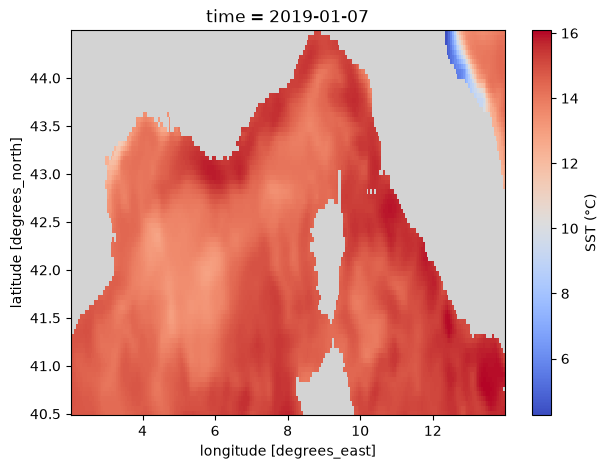

In [9]:
# Map of the coldest day of the record (07-01-2019), in Celsius.
# Blue = cold, red = warm. Land (NaN) in light grey.
sst = ds["analysed_sst"]
day_c = sst.sel(time="2019-01-07") - 273.15

fig, ax = plt.subplots(figsize=(7, 5))
ax.set_facecolor("lightgrey")

day_c.plot(ax=ax, cmap="coolwarm", cbar_kwargs={"label": "SST (°C)"})
plt.show()

***Results***: Temperature range over the full record: minimum 277.40 K (4.25 °C), maximum 303.94 K (30.79 °C). The maximum is in line with Mediterranean summer sea temperatures. The minimum, which I expected a couple of degrees warmer, falls on 07-01-2019 at lat 44.47, lon 12.35: the northern Adriatic, on the northern edge of the bounding box. It is not an isolated value: cells within 2 °C of the record minimum appear on 18 consecutive days (30-12-2018 to 16-01-2019), with 37 cells on 07-01-2019, and they form a single compact patch (map above). I read it as a real cold episode in shallow northern Adriatic water, not a data artefact. Since the patch touches the edge of the box, it probably extends beyond the area I downloaded.